## Visualize the image with BB

### Requirements:
- manually download and unpack refcoco+ at .../dl-lab-final-project/datasets/
- you will then have:

```
dl-lab-final-project/datasets/

|-- refcoco+

|-- |-- instances.json

|-- |-- refs(uns).p
```

### Environment Setup

In [1]:
import os
os.environ['TORCH_HOME'] = '/project/dl2023s/hoos/dl-lab-final-project/cache'
%cd /project/dl2023s/hoos/dl-lab-final-project

/project/dl2023s/hoos/dl-lab-final-project


### Helper Code (required)

In [2]:
import json
from dataclasses import dataclass
from pathlib import Path
from pprint import pprint
from typing import Tuple, List, Optional, Union

import matplotlib.pyplot as plt
from IPython.display import display
from PIL import ImageDraw, ImageFont, Image
from matplotlib import colors as mpl_colors, cm as mpl_cm
from tqdm import tqdm


def load_jsonl(file):
    data_str = Path(file).read_text(encoding="utf-8")
    data = []
    for i, line in enumerate(data_str.splitlines()):
        try:
            data.append(json.loads(line))
        except Exception as e:
            raise RuntimeError(f"Error loading json file {file} line {i}") from e
    return data


def get_bbox_bounds(box_x: float, box_y: float, box_w: float, box_h: float, image_w: int,
                    image_h: int, min_w=32, min_h=32):
    """
    Get the bounding box boundaries for cropping the image.
    Increase the box size if it is too small.

    Args:
        box_x: absolute box coordinates for the given image
        box_y:
        box_w:
        box_h:
        image_w: image size
        image_h:
        min_w: minimum box size
        min_h:

    Returns:
        Cropping parameters tuple (x1, y1, x2, y2)

    """
    # Calculate the center coordinates of the bounding box
    center_x = box_x + (box_w / 2)
    center_y = box_y + (box_h / 2)

    # Calculate the new width and height of the bounding box
    new_w = max(box_w, min_w)
    new_h = max(box_h, min_h)

    # Calculate the new x and y coordinates of the top-left corner of the bounding box
    new_x = center_x - (new_w / 2)
    new_y = center_y - (new_h / 2)

    # Adjust the new x coordinate if the box is too close to the left border
    if new_x < 0:
        new_x = 0
        new_x2 = min(new_x + new_w, image_w)
    else:
        new_x2 = min(new_x + new_w, image_w)
        if new_x2 > image_w:
            new_x2 = image_w
            new_x = max(new_x2 - new_w, 0)

    # Adjust the new y coordinate if the box is too close to the top border
    if new_y < 0:
        new_y = 0
        new_y2 = min(new_y + new_h, image_h)
    else:
        new_y2 = min(new_y + new_h, image_h)
        if new_y2 > image_h:
            new_y2 = image_h
            new_y = max(new_y2 - new_h, 0)

    # Return the cropping boundaries as integers
    return int(new_x), int(new_y), int(new_x2), int(new_y2)


def create_colormap_for_dark_background(
        n: int = 256, inverted=False, scale=1., alpha=1.,
        add_brightness: float = 0.) -> mpl_colors.Colormap:
    """
    Colormap with only light colors that works well for text on dark background.

    Args:
        n: number of discrete colors to generate in the colormap
        inverted: if True, invert the colormap (gives dark colors for bright background)
        scale: downscale the colormap (make it darker, 1.0 = no scaling)
        alpha: alpha value for all colors
        add_brightness: add this value to all color values (0.0 = no change)

    Returns:
        colormap
    """
    ccmap_colors = [
        [128, 128, 255],
        [0, 255, 255],
        [0, 255, 0],
        [255, 255, 0],
        [255, 0, 0],
        [255, 0, 255],
        [255, 255, 255]
    ]

    def _convert(c):
        c = c / 255
        if inverted:
            c = 1 - c
        c_scaled = max(min(c * scale, 1.0), 0.0)
        return c_scaled * (1.0 - add_brightness) + add_brightness

    ccmap_colors_01 = [
        [_convert(a) for a in rgb] + [alpha] for rgb in ccmap_colors
    ]
    ccmap = mpl_colors.LinearSegmentedColormap.from_list('better_nipy', ccmap_colors_01, N=n)
    return ccmap


@dataclass
class ColorGetterForColorMap:
    input_cmap: Union[mpl_colors.Colormap, str]
    start_val: Union[int, float]
    stop_val: Union[int, float]
    return_alpha: bool = False
    return_float: bool = False

    def __post_init__(self):
        self.cmap = self.input_cmap
        if isinstance(self.input_cmap, str):
            self.cmap = plt.get_cmap(self.input_cmap)
        self.norm = mpl_colors.Normalize(vmin=self.start_val, vmax=self.stop_val)
        self.scalar_map = mpl_cm.ScalarMappable(norm=self.norm, cmap=self.cmap)

    def get_color(self, val) -> Union[Tuple[int, int, int, int], Tuple[int, int, int]]:
        rgba = self.scalar_map.to_rgba(val)
        if not self.return_alpha:
            rgba = rgba[:3]
        if not self.return_float:
            rgba = [int(round(a * 255)) for a in rgba]
        return rgba


def create_colorgetter_from_colormap(input_cmap: Union[mpl_colors.Colormap, str],
                                     return_alpha: bool = False,
                                     return_float: bool = False):
    # getter is now function that takes a value in (0, 1) and returns a color
    color_helper = ColorGetterForColorMap(input_cmap, 0, 1, return_alpha=return_alpha,
                                          return_float=return_float)
    return color_helper.get_color


def draw_bounding_boxes_pil(
        image: Image.Image,
        boxes: List[Tuple[float, float, float, float]],  # x, y, w, h
        labels: Optional[List[str]] = None,
        colors: Optional[List[Tuple[int, int, int]]] = None,
        width: int = 3,
        font: str = "DejaVuSans.ttf",
        font_size: int = 14,
        cmap: Optional[Union[str, mpl_colors.Colormap]] = None,
):
    draw = ImageDraw.Draw(image)
    font = ImageFont.truetype(font, font_size)

    if colors is None:
        if cmap is None:
            cmap = create_colormap_for_dark_background(add_brightness=0.5)
        # automatically generate a bunch of colors from the colormap
        getter = create_colorgetter_from_colormap(cmap)
        colors = [tuple(getter(i / len(boxes))) for i in range(len(boxes))]

    if labels is None:
        labels = [str(i) for i in range(len(boxes))]

    for box, label, color in zip(boxes, labels, colors):
        x, y, w, h = box
        x1, y1, x2, y2 = get_bbox_bounds(x, y, w, h, image.width, image.height, min_w=0, min_h=0)
        draw.rectangle([(x1, y1), (x2, y2)], outline=color, width=width)

        text_args = dict(font=font, stroke_width=2)
        (t_left, t_top, t_right, t_bottom) = draw.textbbox((0, 0), label, **text_args)
        # text_width, text_height = draw.textsize(label, **text_args)
        text_width, text_height = t_right - t_left, t_bottom - t_top
        text_x = min(x1 + width + 2, image.width - text_width)
        text_y = min(y1 + width + 2, image.height - text_height)
        draw.text((text_x, text_y), label, fill=color, anchor="lt",
                  stroke_fill="black", **text_args)

    return image

Matplotlib is building the font cache; this may take a moment.


## Visual Feature Extraction

In [3]:
from lavis.models.eva_vit import create_eva_vit_g
from lavis.models.blip2_models.blip2 import LayerNorm

visual_encoder = create_eva_vit_g(img_size=224, precision=None)
ln_vision = LayerNorm(visual_encoder.num_features)

/project/dl2023s/hoos/conda_envs/localization/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from torchvision import transforms
from torchvision.transforms.functional import InterpolationMode


def resize_bbox(bboxes, image_width, image_height, new_image_width, new_image_height):
    """
    Resize bounding boxes according to image resize.
    Args:
        bboxes (list[float]): list of bounding boxes [x, y, w, h]
        image_width (int): width of the image
        image_height (int): height of the image
        new_image_width (int): resized image width
        new_image_height (int): resized image height
    Returns:
        list[float]: resized bounding boxes
    """
    bboxes = np.array(bboxes, dtype=np.float32)
    bboxes[:, 0] = bboxes[:, 0] * new_image_width / image_width
    bboxes[:, 1] = bboxes[:, 1] * new_image_height / image_height
    bboxes[:, 2] = bboxes[:, 2] * new_image_width / image_width
    bboxes[:, 3] = bboxes[:, 3] * new_image_height / image_height

    return bboxes.tolist()


vision_transform = transforms.Compose(
    [
        transforms.Resize(
            (224, 224),
            interpolation=InterpolationMode.BICUBIC,
        ),
        transforms.ToTensor(),
        # self.normalize,
    ]
)


In [6]:
from PIL import Image

image_filepath = "./notebooks/COCO_train2014_000000524291.jpg"
image = Image.open(image_filepath).convert("RGB")

transformed_image = vision_transform(image)
image_embeds = ln_vision(visual_encoder(transformed_image.unsqueeze(0)))

image_embeds.shape


torch.Size([1, 257, 1408])

In [7]:
import numpy as np

cls_token, vis_feats = image_embeds[:, 0], image_embeds[:, 1:]
batch_size, width_squared, hidden_dim = vis_feats.shape

# assert width_squared is perfect squared
assert width_squared == int(np.sqrt(width_squared)) ** 2
width = int(np.sqrt(width_squared))

vis_feats_view = vis_feats.view(batch_size, width, width, hidden_dim)
vis_feats_view.shape

torch.Size([1, 16, 16, 1408])

In [8]:
import json
import pickle
instances = json.load(open("./datasets/refcoco+/instances.json", "r"))
refs = pickle.load(open("./datasets/refcoco+/refs(unc).p", "rb"))

In [13]:
import random

image_id = 524291

relevant_ann_id_to_ref_id = {}
for i, ref in enumerate(refs):
    if ref['image_id'] == image_id:
        relevant_ann_id_to_ref_id[ref['ann_id']] = i

boxes, captions = [], []
relevant_ann_id = relevant_ann_id_to_ref_id.keys()
for ann in instances['annotations']:
    if ann['id'] in relevant_ann_id:
        boxes.append(ann['bbox'])
        ref_id = relevant_ann_id_to_ref_id[ann['id']]
        captions.append(random.choice(refs[ref_id]['sentences'])['raw'])

In [14]:
import torch

# mask = torch.zeros(width, width, hidden_dim, dtype=bool)
mask = torch.zeros(len(boxes), width, width, dtype=int)

boxes_normalized = np.array(resize_bbox(boxes, image.width, image.height, 1, 1))
boxes_in_patch_coords = boxes_normalized * width

# discretize the boxes into a slightly larger boxes
for i, box in enumerate(boxes_in_patch_coords):
    x, y, w, h = box
    x1, y1 = x, y
    x2, y2 = x + w, y + h

    x1, y1 = np.floor([x1, y1]).astype(int)
    x2, y2 = np.ceil([x2, y2]).astype(int)

    mask[i, y1:y2, x1:x2] = 1

mask

tensor([[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]],

        [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

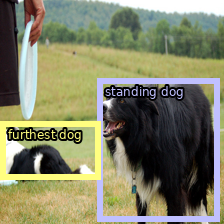

In [15]:
# transform tensor to PIL image
transformed_pil_image = transforms.ToPILImage()(transformed_image)
transformed_bbox = resize_bbox(boxes, image.width, image.height, transformed_pil_image.width, transformed_pil_image.height)
image_with_boxes = draw_bounding_boxes_pil(transformed_pil_image, transformed_bbox, captions, font_size=12, width=6)
display(image_with_boxes)

In [16]:
extracted_vis_feats_view = vis_feats_view * mask.unsqueeze(-1)
extracted_vis_feats = extracted_vis_feats_view.view(batch_size, len(boxes), -1, hidden_dim)
extracted_vis_feats.shape

torch.Size([1, 2, 256, 1408])